# 08B — Endpoint-padding diagnostic

## Objective

Notebook 08 showed that the candidate-call frontend works well for most species, but two cases deserve
inspection before freezing segmentation:

- `f04`: only about 80% of annotated calls reached the chosen **50% coverage** criterion, even with the
  most permissive tested `C`;
- `f10`: call recall was high, but candidate-duration burden was large.

The failure list for `f04` contained many calls with coverage just below 0.50. That pattern is consistent
with **candidate endpoints being slightly too short**, rather than complete failure to detect the call.

This notebook tests that hypothesis with a controlled experiment:

> keep every candidate found by notebook 08 exactly the same, then expand its start/end by a small
> symmetric temporal padding.

No filters, `C`, moving average, GMM, PLP feature, LLR threshold, or pond audio is changed.

The padding grid is:

`0, 10, 20, 30, 50, 75, 100, 150, 200 ms`

The main questions are:

1. Does modest padding raise `f04` recall from ~80% toward ≥95%?
2. How much candidate-duration burden does that cost?
3. Does `f10` benefit meaningfully, or does padding merely make an already-large candidate set larger?
4. Are improvements consistent across recordings or dominated by one WAV?

This is a **diagnostic notebook**. It does not overwrite the segmentation configuration from notebook 08.

In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf

from scipy.io import loadmat

try:
    from dotenv import load_dotenv
except ImportError as exc:
    raise ImportError(
        "Notebook 08B needs python-dotenv to resolve MENDELEY_CALL_DIR."
    ) from exc

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 220)
pd.set_option("display.max_columns", 120)

CWD = Path.cwd().resolve()
REPO_ROOT = CWD.parent if CWD.name == "notebooks" else CWD

PROCESSED_DIR = REPO_ROOT / "data" / "processed"

SEGMENTATION_DIR = (
    PROCESSED_DIR
    / "candidate_call_segmentation"
)

RESULTS_DIR = (
    SEGMENTATION_DIR
    / "endpoint_padding_diagnostic"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CALLS_PATH = PROCESSED_DIR / "calls.csv"

CANDIDATES_PATH = (
    SEGMENTATION_DIR
    / "selected_dataset1_candidates.csv"
)

SELECTED_METRICS_PATH = (
    SEGMENTATION_DIR
    / "selected_segmentation_metrics.csv"
)

CONFIG_PATH = (
    SEGMENTATION_DIR
    / "selected_segmentation_configuration.json"
)

for path in (
    CALLS_PATH,
    CANDIDATES_PATH,
    SELECTED_METRICS_PATH,
    CONFIG_PATH,
):
    if not path.exists():
        raise FileNotFoundError(
            f"Missing notebook-08 output: {path}"
        )

load_dotenv(REPO_ROOT / ".env")

mendeley_value = os.environ.get(
    "MENDELEY_CALL_DIR"
)

if not mendeley_value:
    raise RuntimeError(
        "MENDELEY_CALL_DIR is not defined in .env."
    )

MENDELEY_CALL_DIR = Path(
    mendeley_value
).expanduser()

if not MENDELEY_CALL_DIR.is_dir():
    raise FileNotFoundError(
        f"MENDELEY_CALL_DIR does not exist: {MENDELEY_CALL_DIR}"
    )

print("Repository root :", REPO_ROOT)
print("Segmentation dir:", SEGMENTATION_DIR)
print("08B results     :", RESULTS_DIR)

Repository root : C:\Users\sofia\Projects\PUCE\frog-presence-replication
Segmentation dir: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation
08B results     : C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation\endpoint_padding_diagnostic


## 2. Load notebook-08 outputs

In [2]:
calls = (
    pd.read_csv(CALLS_PATH)
    .copy()
    .reset_index(drop=True)
)

candidates = (
    pd.read_csv(CANDIDATES_PATH)
    .copy()
)

selected_metrics = (
    pd.read_csv(SELECTED_METRICS_PATH)
    .copy()
)

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8",
) as f:
    segmentation_config = json.load(f)

USABLE_CODES = tuple(
    segmentation_config[
        "selection"
    ][
        "C_by_code"
    ].keys()
)

C_BY_CODE = {
    code: float(value)
    for code, value
    in segmentation_config[
        "selection"
    ][
        "C_by_code"
    ].items()
}

print("Usable codes:", USABLE_CODES)

display(
    selected_metrics[
        [
            "code",
            "C",
            "call_recall_50",
            "annotation_coverage",
            "candidate_overlap_share",
            "candidate_burden_ratio",
            "n_candidates",
        ]
    ].round(4)
)

Usable codes: ('f01', 'f02', 'f03', 'f04', 'f05', 'f06', 'f07', 'f08', 'f10')


,code,C,call_recall_50,annotation_coverage,candidate_overlap_share,candidate_burden_ratio,n_candidates
0,f01,4.00,0.9592,0.5718,0.5463,1.0467,273
1,f02,2.00,0.9596,0.6596,0.2469,2.6711,608
2,f03,4.00,0.9645,0.6582,0.3546,1.8560,708
3,f04,10.00,0.7957,0.5852,0.1016,5.7617,2037
4,f05,2.50,0.9765,0.5695,0.3106,1.8337,1289
5,f06,4.00,1.0000,0.7473,0.3537,2.1127,200
6,f07,4.00,0.9802,0.8645,0.2004,4.3136,698
7,f08,1.75,0.9792,0.7605,0.5793,1.3128,494
8,f10,4.00,0.9589,0.5953,0.1051,5.6653,2970


## 3. Reconstruct manual call endpoints

Notebook 02 is left untouched. We repeat the same safe endpoint reconstruction used in notebooks 05 and
08, then verify row-by-row alignment against `calls.csv`.

In [3]:
SEGMENT_DIR = (
    MENDELEY_CALL_DIR
    / "segment files"
)

PAPER_TABLE1 = pd.DataFrame(
    [
        ("f01", "Boana alfaroi", "cantos_alfaroi.mat"),
        ("f02", "Dendropsophus bifurcus", "cantos_bifurcus.mat"),
        ("f03", "Boana cinerascens", "cantos_cinerascens.mat"),
        ("f04", "Pristimantis conspicillatus", "cantos_conspicillatus.mat"),
        ("f05", "Leptodactylus discodactylus", "cantos_discodactylus.mat"),
        ("f06", "Osteocephalus fuscifacies", "cantos_fuscifacies.mat"),
        ("f07", "Boana lanciformis", "cantos_lanciformis.mat"),
        ("f08", "Rhinella margaritifera", "cantos_margaritifer.mat"),
        ("f09", "Dendropsophus parviceps", "cantos_parviceps.mat"),
        ("f10", "Engystomops petersi", "cantos_petersi.mat"),
    ],
    columns=[
        "code",
        "species",
        "segment_file",
    ],
)

WAV_ON_DISK = {
    path.name.lower(): path
    for path
    in MENDELEY_CALL_DIR.rglob("*")
    if path.suffix.lower() == ".wav"
}


def read_calls_from_segment_file(filename):
    mat = loadmat(
        SEGMENT_DIR / filename
    )

    if "cantos" not in mat:
        raise KeyError(
            f"{filename} does not contain 'cantos'."
        )

    rows = []

    for recording_index, (
        wav_path,
        intervals,
        rate,
    ) in enumerate(mat["cantos"]):

        wav = Path(
            str(wav_path[0]).replace(
                "\\",
                "/",
            )
        ).name

        sr = int(
            rate[0][0]
        )

        for start, end in intervals:
            rows.append({
                "segment_file":
                    filename,
                "recording":
                    recording_index,
                "wav":
                    wav,
                "rate":
                    sr,
                "start":
                    int(start),
                "end":
                    int(end),
            })

    return pd.DataFrame(rows)


annotated = pd.concat(
    [
        read_calls_from_segment_file(
            filename
        )
        for filename
        in PAPER_TABLE1[
            "segment_file"
        ]
    ],
    ignore_index=True,
)

annotated = annotated.merge(
    PAPER_TABLE1,
    on="segment_file",
    how="left",
)

annotated["seconds"] = (
    annotated["end"]
    - annotated["start"]
) / annotated["rate"]

annotated["on_disk"] = (
    annotated["wav"]
    .str.lower()
    .isin(WAV_ON_DISK)
)

available_annotations = (
    annotated[
        annotated["on_disk"]
    ]
    .reset_index(drop=True)
)

if len(available_annotations) != len(calls):
    raise RuntimeError(
        "Endpoint reconstruction and calls.csv have different row counts."
    )

alignment = pd.DataFrame({
    "code":
        calls["code"].astype(str).to_numpy()
        == available_annotations["code"].astype(str).to_numpy(),
    "species":
        calls["species"].astype(str).to_numpy()
        == available_annotations["species"].astype(str).to_numpy(),
    "wav":
        calls["wav"].astype(str).str.lower().to_numpy()
        == available_annotations["wav"].astype(str).str.lower().to_numpy(),
    "recording":
        calls["recording"].astype(int).to_numpy()
        == available_annotations["recording"].astype(int).to_numpy(),
    "rate":
        calls["rate"].astype(int).to_numpy()
        == available_annotations["rate"].astype(int).to_numpy(),
    "seconds":
        np.isclose(
            calls["seconds"].astype(float).to_numpy(),
            available_annotations["seconds"].astype(float).to_numpy(),
            atol=1e-10,
            rtol=1e-10,
        ),
})

display(
    alignment.mean().rename(
        "share_matching"
    ).to_frame()
)

if not alignment.to_numpy().all():
    bad = np.where(
        ~alignment.all(axis=1).to_numpy()
    )[0]
    raise RuntimeError(
        f"Endpoint reconstruction failed for {len(bad)} calls."
    )

calls["call_id"] = [
    f"call_{i:04d}"
    for i
    in range(len(calls))
]

calls["start"] = (
    available_annotations["start"]
    .astype(int)
    .to_numpy()
)

calls["end"] = (
    available_annotations["end"]
    .astype(int)
    .to_numpy()
)

calls["recording_group"] = (
    calls["wav"]
    .astype(str)
    .str.strip()
    .str.lower()
)

calls["resolved_wav"] = [
    str(
        WAV_ON_DISK[
            wav.lower()
        ]
    )
    for wav
    in calls["wav"]
]

usable_calls = (
    calls[
        calls["code"].isin(
            USABLE_CODES
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Endpoint alignment: 100%")
print("calls.csv modified on disk: NO")

,share_matching
code,1.0
species,1.0
wav,1.0
recording,1.0
rate,1.0
seconds,1.0


Endpoint alignment: 100%
calls.csv modified on disk: NO


## 4. Padding grid

Padding is applied symmetrically to every candidate endpoint.

Candidates are clipped to `[0, WAV duration]`, then merged when they overlap after padding.

In [4]:
PADDING_MS_GRID = (
    0,
    10,
    20,
    30,
    50,
    75,
    100,
    150,
    200,
)

CALL_COVERAGE_TARGET = 0.50
TARGET_CALL_RECALL = 0.95

FOCUS_CODES = (
    "f04",
    "f10",
)

print("Padding grid (ms):", PADDING_MS_GRID)
print("Focus species     :", FOCUS_CODES)

Padding grid (ms): (0, 10, 20, 30, 50, 75, 100, 150, 200)
Focus species     : ('f04', 'f10')


In [5]:
def merge_intervals(intervals):
    intervals = sorted(
        (
            int(start),
            int(end),
        )
        for start, end
        in intervals
        if end > start
    )

    if not intervals:
        return []

    merged = [
        list(
            intervals[0]
        )
    ]

    for start, end in intervals[1:]:
        previous = merged[-1]

        if start <= previous[1]:
            previous[1] = max(
                previous[1],
                end,
            )
        else:
            merged.append(
                [
                    start,
                    end,
                ]
            )

    return [
        (
            start,
            end,
        )
        for start, end
        in merged
    ]


def covered_length(
    target_start,
    target_end,
    intervals,
):
    pieces = []

    for start, end in intervals:
        overlap_start = max(
            target_start,
            start,
        )
        overlap_end = min(
            target_end,
            end,
        )

        if overlap_end > overlap_start:
            pieces.append(
                (
                    overlap_start,
                    overlap_end,
                )
            )

    return sum(
        end - start
        for start, end
        in merge_intervals(
            pieces
        )
    )


def pad_candidate_intervals(
    candidate_group,
    sr,
    n_samples,
    padding_ms,
):
    pad_samples = int(
        round(
            sr
            * (
                padding_ms
                / 1000.0
            )
        )
    )

    padded = []

    for row in candidate_group.itertuples(
        index=False
    ):
        start = max(
            0,
            int(row.start_sample)
            - pad_samples,
        )

        end = min(
            n_samples,
            int(row.end_sample)
            + pad_samples,
        )

        if end > start:
            padded.append(
                (
                    start,
                    end,
                )
            )

    return merge_intervals(
        padded
    )


def evaluate_padded_intervals(
    ground_truth,
    padded_intervals,
    sr,
):
    call_rows = []

    for row in ground_truth.itertuples(
        index=False
    ):
        gt_start = int(
            row.start
        )
        gt_end = int(
            row.end
        )
        gt_length = max(
            1,
            gt_end - gt_start,
        )

        covered = covered_length(
            gt_start,
            gt_end,
            padded_intervals,
        )

        coverage = (
            covered
            / gt_length
        )

        call_rows.append({
            "call_id":
                row.call_id,
            "code":
                row.code,
            "wav":
                row.wav,
            "recording_group":
                row.recording_group,
            "coverage":
                coverage,
            "any_overlap":
                coverage > 0,
            "covered_50pct":
                coverage
                >= CALL_COVERAGE_TARGET,
        })

    call_metrics = pd.DataFrame(
        call_rows
    )

    gt_intervals = merge_intervals([
        (
            int(row.start),
            int(row.end),
        )
        for row
        in ground_truth.itertuples(
            index=False
        )
    ])

    total_gt = sum(
        end - start
        for start, end
        in gt_intervals
    )

    total_candidate = sum(
        end - start
        for start, end
        in padded_intervals
    )

    gt_covered = sum(
        covered_length(
            start,
            end,
            padded_intervals,
        )
        for start, end
        in gt_intervals
    )

    candidate_overlap = sum(
        covered_length(
            start,
            end,
            gt_intervals,
        )
        for start, end
        in padded_intervals
    )

    summary = {
        "n_gt_calls":
            len(ground_truth),
        "call_recall_any":
            float(
                call_metrics["any_overlap"].mean()
            ),
        "call_recall_50":
            float(
                call_metrics["covered_50pct"].mean()
            ),
        "median_call_coverage":
            float(
                call_metrics["coverage"].median()
            ),
        "annotation_coverage":
            (
                gt_covered / total_gt
                if total_gt
                else np.nan
            ),
        "candidate_overlap_share":
            (
                candidate_overlap / total_candidate
                if total_candidate
                else np.nan
            ),
        "candidate_seconds":
            total_candidate / sr,
        "annotated_seconds_union":
            total_gt / sr,
        "candidate_burden_ratio":
            (
                total_candidate / total_gt
                if total_gt
                else np.nan
            ),
        "n_merged_candidates":
            len(padded_intervals),
    }

    return summary, call_metrics

## 5. Run padding sweep

The original candidate detections from notebook 08 are never altered on disk.

In [6]:
recording_rows = []
call_metric_blocks = []

grouped = list(
    usable_calls.groupby(
        [
            "code",
            "recording_group",
            "resolved_wav",
        ],
        sort=True,
    )
)

for group_index, (
    (
        code,
        recording_group,
        resolved_wav,
    ),
    gt_group,
) in enumerate(
    grouped,
    start=1,
):

    candidate_group = (
        candidates[
            (
                candidates["code"]
                == code
            )
            & (
                candidates["recording_group"]
                == recording_group
            )
        ]
        .copy()
    )

    _, sr = sf.read(
        resolved_wav,
        frames=1,
        always_2d=False,
        dtype="float64",
    )
    sr = int(sr)

    info = sf.info(
        resolved_wav
    )
    n_samples = int(
        info.frames
    )

    expected_sr = int(
        gt_group["rate"].iloc[0]
    )

    if sr != expected_sr:
        raise RuntimeError(
            f"Sample-rate mismatch for {resolved_wav}."
        )

    print(
        f"{group_index:>3}/{len(grouped)} | "
        f"{code} | {Path(resolved_wav).name}"
    )

    for padding_ms in PADDING_MS_GRID:

        padded_intervals = (
            pad_candidate_intervals(
                candidate_group=candidate_group,
                sr=sr,
                n_samples=n_samples,
                padding_ms=padding_ms,
            )
        )

        summary, call_metrics = (
            evaluate_padded_intervals(
                ground_truth=gt_group,
                padded_intervals=padded_intervals,
                sr=sr,
            )
        )

        recording_rows.append({
            "code":
                code,
            "recording_group":
                recording_group,
            "wav":
                Path(
                    resolved_wav
                ).name,
            "selected_C":
                float(
                    C_BY_CODE[
                        code
                    ]
                ),
            "padding_ms":
                int(
                    padding_ms
                ),
            **summary,
        })

        call_metrics[
            "padding_ms"
        ] = int(
            padding_ms
        )

        call_metric_blocks.append(
            call_metrics
        )

recording_sweep = pd.DataFrame(
    recording_rows
)

call_sweep = pd.concat(
    call_metric_blocks,
    ignore_index=True,
)

print("Recording-padding rows:", len(recording_sweep))
print("Call-padding rows     :", len(call_sweep))

  1/66 | f01 | 1101.WAV
  2/66 | f01 | 1102.WAV
  3/66 | f01 | 1103.WAV
  4/66 | f01 | 1105.WAV
  5/66 | f01 | 1106.WAV
  6/66 | f02 | D-bifircus-D-parviceps-LS100120.WAV
  7/66 | f02 | D-bifurcus-sc10743.wav
  8/66 | f02 | Dbifurcus2.WAV
  9/66 | f02 | Drhodopeplusbifurcus2_Daniel1.WAV
 10/66 | f02 | LS100120.WAV
 11/66 | f02 | LS100303 D. bifurcus sc38590mono.WAV
 12/66 | f02 | LS100536.WAV
 13/66 | f02 | LS100582.WAV
 14/66 | f02 | LS100584.WAV
 15/66 | f02 | LS100594.WAV
 16/66 | f03 | Hcinerascens.WAV
 17/66 | f03 | Hcinerascens2_Daniel.WAV
 18/66 | f03 | Hcinerascens3.WAV
 19/66 | f03 | LS100305_Daniel1.WAV
 20/66 | f03 | LS100306.WAV
 21/66 | f03 | LS100444 H. cinerascensmono.WAV
 22/66 | f03 | LS100459 sc44991-92.WAV
 23/66 | f03 | LS100732.WAV
 24/66 | f04 | LS100307.WAV
 25/66 | f04 | LS100308- Pristimantis conspicillatus.WAV
 26/66 | f04 | LS100309sc37073.WAV
 27/66 | f04 | LS100313- Pristimantis conspicillatus.WAV
 28/66 | f04 | LS100319Pconspicillatus.wav
 29/66 | f04 | LS

## 6. Aggregate by species and padding

In [7]:
def weighted_mean(
    values,
    weights,
):
    values = np.asarray(
        values,
        dtype=float,
    )
    weights = np.asarray(
        weights,
        dtype=float,
    )

    mask = (
        np.isfinite(values)
        & np.isfinite(weights)
        & (
            weights > 0
        )
    )

    if not np.any(mask):
        return np.nan

    return float(
        np.average(
            values[mask],
            weights=weights[mask],
        )
    )


species_rows = []

for (
    code,
    padding_ms,
), group in recording_sweep.groupby(
    [
        "code",
        "padding_ms",
    ],
    sort=True,
):

    total_candidate_seconds = float(
        group["candidate_seconds"].sum()
    )

    total_annotated_seconds = float(
        group["annotated_seconds_union"].sum()
    )

    species_rows.append({
        "code":
            code,
        "padding_ms":
            int(
                padding_ms
            ),
        "n_recordings":
            group[
                "recording_group"
            ].nunique(),
        "n_gt_calls":
            int(
                group["n_gt_calls"].sum()
            ),
        "call_recall_any":
            weighted_mean(
                group["call_recall_any"],
                group["n_gt_calls"],
            ),
        "call_recall_50":
            weighted_mean(
                group["call_recall_50"],
                group["n_gt_calls"],
            ),
        "median_recording_call_coverage":
            float(
                group[
                    "median_call_coverage"
                ].median()
            ),
        "annotation_coverage":
            weighted_mean(
                group["annotation_coverage"],
                group["annotated_seconds_union"],
            ),
        "candidate_overlap_share":
            weighted_mean(
                group["candidate_overlap_share"],
                group[
                    "candidate_seconds"
                ].replace(
                    0,
                    np.nan,
                ),
            ),
        "candidate_seconds":
            total_candidate_seconds,
        "annotated_seconds_union":
            total_annotated_seconds,
        "candidate_burden_ratio":
            (
                total_candidate_seconds
                / total_annotated_seconds
                if total_annotated_seconds
                else np.nan
            ),
        "n_merged_candidates":
            int(
                group[
                    "n_merged_candidates"
                ].sum()
            ),
    })

species_sweep = pd.DataFrame(
    species_rows
)

display(
    species_sweep[
        species_sweep["code"].isin(
            FOCUS_CODES
        )
    ].round(4)
)

,code,padding_ms,n_recordings,n_gt_calls,call_recall_any,call_recall_50,median_recording_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio,n_merged_candidates
27,f04,0,9,186,1.0000,0.7957,0.5714,0.5852,0.1016,449.0700,77.94,5.7617,2034
28,f04,10,9,186,1.0000,0.9570,0.6111,0.6302,0.1003,489.7241,77.94,6.2833,2033
29,f04,20,9,186,1.0000,1.0000,0.6579,0.6741,0.0992,529.7341,77.94,6.7967,1907
30,f04,30,9,186,1.0000,1.0000,0.7105,0.7170,0.0985,567.3541,77.94,7.2794,1807
31,f04,50,9,186,1.0000,1.0000,0.8095,0.8006,0.0979,637.0341,77.94,8.1734,1640
32,f04,75,9,186,1.0000,1.0000,0.9251,0.9013,0.0982,715.0591,77.94,9.1745,1462
33,f04,100,9,186,1.0000,1.0000,0.9978,0.9782,0.0971,784.8233,77.94,10.0696,1303
34,f04,150,9,186,1.0000,1.0000,1.0000,1.0000,0.0862,904.4233,77.94,11.6041,1086
35,f04,200,9,186,1.0000,1.0000,1.0000,1.0000,0.0776,1003.9333,77.94,12.8808,903
72,f10,0,12,316,0.9968,0.9589,0.5812,0.5953,0.1051,759.1500,134.00,5.6653,2961


## 7. Focus on `f04`

This is the key diagnostic.

If recall jumps sharply with only 20–50 ms padding, the 08 failure was mostly endpoint truncation.
If recall remains low even at 100–200 ms, the issue is more likely missed/fragmented events rather than
simple endpoint bias.

,code,padding_ms,n_recordings,n_gt_calls,call_recall_any,call_recall_50,median_recording_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio,n_merged_candidates
0,f04,0,9,186,1.0,0.7957,0.5714,0.5852,0.1016,449.0700,77.94,5.7617,2034
1,f04,10,9,186,1.0,0.9570,0.6111,0.6302,0.1003,489.7241,77.94,6.2833,2033
2,f04,20,9,186,1.0,1.0000,0.6579,0.6741,0.0992,529.7341,77.94,6.7967,1907
3,f04,30,9,186,1.0,1.0000,0.7105,0.7170,0.0985,567.3541,77.94,7.2794,1807
4,f04,50,9,186,1.0,1.0000,0.8095,0.8006,0.0979,637.0341,77.94,8.1734,1640
5,f04,75,9,186,1.0,1.0000,0.9251,0.9013,0.0982,715.0591,77.94,9.1745,1462
6,f04,100,9,186,1.0,1.0000,0.9978,0.9782,0.0971,784.8233,77.94,10.0696,1303
7,f04,150,9,186,1.0,1.0000,1.0000,1.0000,0.0862,904.4233,77.94,11.6041,1086
8,f04,200,9,186,1.0,1.0000,1.0000,1.0000,0.0776,1003.9333,77.94,12.8808,903


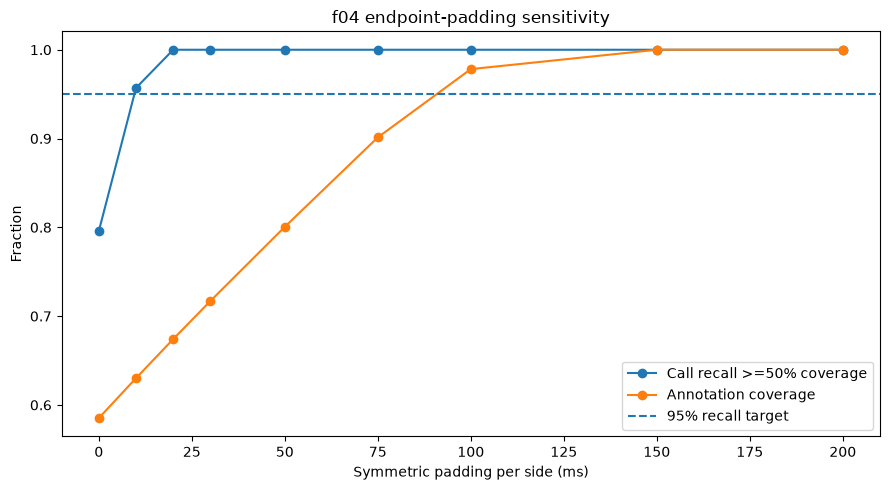

In [8]:
f04_sweep = (
    species_sweep[
        species_sweep["code"]
        == "f04"
    ]
    .sort_values(
        "padding_ms"
    )
    .reset_index(drop=True)
)

display(
    f04_sweep.round(4)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    f04_sweep["padding_ms"],
    f04_sweep["call_recall_50"],
    marker="o",
    label="Call recall >=50% coverage",
)

ax.plot(
    f04_sweep["padding_ms"],
    f04_sweep["annotation_coverage"],
    marker="o",
    label="Annotation coverage",
)

ax.axhline(
    TARGET_CALL_RECALL,
    linestyle="--",
    label="95% recall target",
)

ax.set(
    title="f04 endpoint-padding sensitivity",
    xlabel="Symmetric padding per side (ms)",
    ylabel="Fraction",
)

ax.legend()

plt.tight_layout()
plt.show()

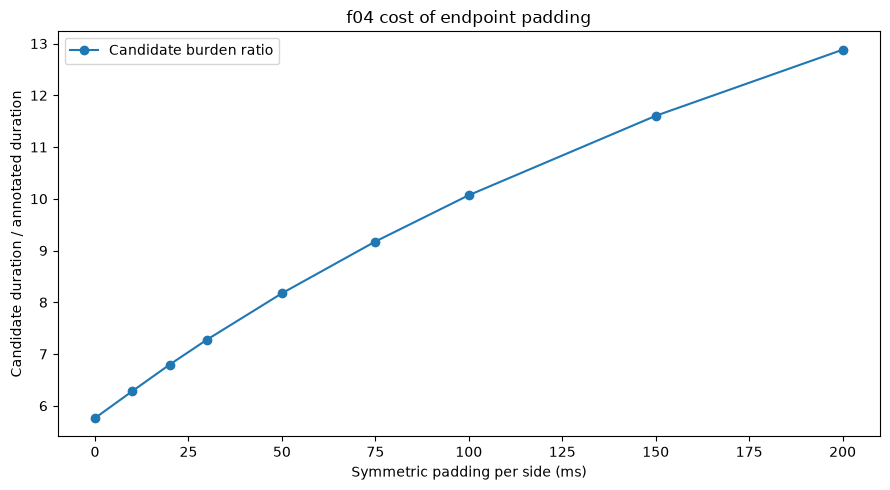

In [9]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    f04_sweep["padding_ms"],
    f04_sweep["candidate_burden_ratio"],
    marker="o",
    label="Candidate burden ratio",
)

ax.set(
    title="f04 cost of endpoint padding",
    xlabel="Symmetric padding per side (ms)",
    ylabel="Candidate duration / annotated duration",
)

ax.legend()

plt.tight_layout()
plt.show()

## 8. Focus on `f10`

`f10` already has high recall. Here padding is worthwhile only if it repairs meaningful endpoint coverage
without making the already-large candidate burden materially worse.

,code,padding_ms,n_recordings,n_gt_calls,call_recall_any,call_recall_50,median_recording_call_coverage,annotation_coverage,candidate_overlap_share,candidate_seconds,annotated_seconds_union,candidate_burden_ratio,n_merged_candidates
0,f10,0,12,316,0.9968,0.9589,0.5812,0.5953,0.1051,759.1500,134.0,5.6653,2961
1,f10,10,12,316,0.9968,0.9905,0.6277,0.6370,0.1043,818.3115,134.0,6.1068,2958
2,f10,20,12,316,0.9968,0.9905,0.6742,0.6787,0.1038,876.3015,134.0,6.5396,2736
3,f10,30,12,316,0.9968,0.9905,0.7208,0.7197,0.1037,929.8315,134.0,6.9390,2501
4,f10,50,12,316,0.9968,0.9905,0.8132,0.7979,0.1044,1024.4615,134.0,7.6452,2186
5,f10,75,12,316,0.9968,0.9968,0.8904,0.8835,0.1048,1129.1208,134.0,8.4263,1981
6,f10,100,12,316,0.9968,0.9968,0.9568,0.9532,0.1042,1225.4781,134.0,9.1454,1858
7,f10,150,12,316,0.9968,0.9968,1.0000,0.9960,0.0952,1401.1881,134.0,10.4566,1644
8,f10,200,12,316,0.9968,0.9968,1.0000,0.9967,0.0857,1558.0081,134.0,11.6269,1481


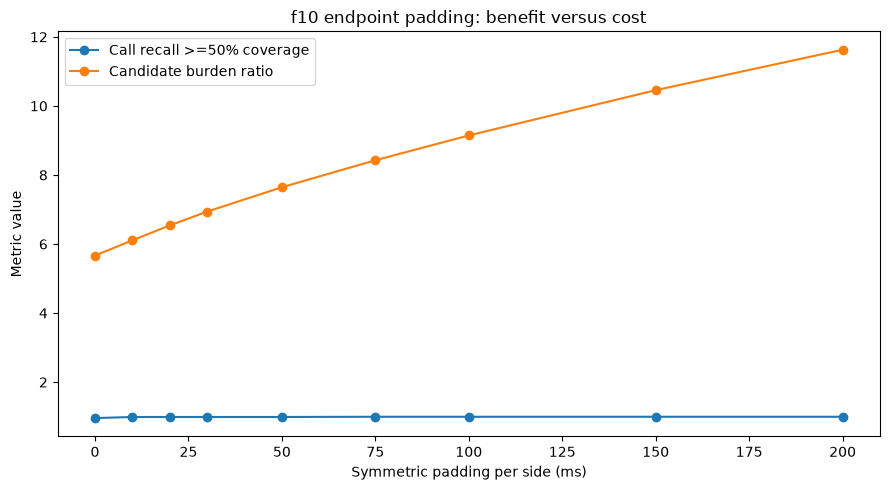

In [10]:
f10_sweep = (
    species_sweep[
        species_sweep["code"]
        == "f10"
    ]
    .sort_values(
        "padding_ms"
    )
    .reset_index(drop=True)
)

display(
    f10_sweep.round(4)
)

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    f10_sweep["padding_ms"],
    f10_sweep["call_recall_50"],
    marker="o",
    label="Call recall >=50% coverage",
)

ax.plot(
    f10_sweep["padding_ms"],
    f10_sweep["candidate_burden_ratio"],
    marker="o",
    label="Candidate burden ratio",
)

ax.set(
    title="f10 endpoint padding: benefit versus cost",
    xlabel="Symmetric padding per side (ms)",
    ylabel="Metric value",
)

ax.legend()

plt.tight_layout()
plt.show()

## 9. Minimum padding that reaches the recall target

This table is descriptive only. It does **not** automatically modify notebook 08's configuration.

In [11]:
target_rows = []

for code in USABLE_CODES:

    subset = (
        species_sweep[
            species_sweep["code"]
            == code
        ]
        .sort_values(
            "padding_ms"
        )
    )

    feasible = (
        subset[
            subset["call_recall_50"]
            >= TARGET_CALL_RECALL
        ]
    )

    if not feasible.empty:
        chosen = feasible.iloc[0]

        target_rows.append({
            "code":
                code,
            "minimum_padding_ms_for_95pct":
                int(
                    chosen["padding_ms"]
                ),
            "call_recall_50":
                float(
                    chosen["call_recall_50"]
                ),
            "candidate_burden_ratio":
                float(
                    chosen["candidate_burden_ratio"]
                ),
            "annotation_coverage":
                float(
                    chosen["annotation_coverage"]
                ),
            "target_reached":
                True,
        })

    else:
        best = (
            subset
            .sort_values(
                [
                    "call_recall_50",
                    "padding_ms",
                ],
                ascending=[
                    False,
                    True,
                ],
            )
            .iloc[0]
        )

        target_rows.append({
            "code":
                code,
            "minimum_padding_ms_for_95pct":
                np.nan,
            "call_recall_50":
                float(
                    best["call_recall_50"]
                ),
            "candidate_burden_ratio":
                float(
                    best["candidate_burden_ratio"]
                ),
            "annotation_coverage":
                float(
                    best["annotation_coverage"]
                ),
            "target_reached":
                False,
        })

minimum_padding_table = pd.DataFrame(
    target_rows
)

display(
    minimum_padding_table.round(4)
)

,code,minimum_padding_ms_for_95pct,call_recall_50,candidate_burden_ratio,annotation_coverage,target_reached
0,f01,0,0.9592,1.0467,0.5718,True
1,f02,0,0.9596,2.6711,0.6596,True
2,f03,0,0.9645,1.8560,0.6582,True
3,f04,10,0.9570,6.2833,0.6302,True
4,f05,0,0.9765,1.8337,0.5695,True
5,f06,0,1.0000,2.1127,0.7473,True
6,f07,0,0.9802,4.3136,0.8645,True
7,f08,0,0.9792,1.3128,0.7605,True
8,f10,0,0.9589,5.6653,0.5953,True


## 10. Per-recording `f04` behavior

This tells us whether improvement is broad or whether one source WAV dominates the result.

In [12]:
f04_recording_sweep = (
    recording_sweep[
        recording_sweep["code"]
        == "f04"
    ]
    .copy()
)

pivot_f04 = (
    f04_recording_sweep
    .pivot_table(
        index=[
            "recording_group",
            "wav",
            "n_gt_calls",
        ],
        columns="padding_ms",
        values="call_recall_50",
    )
    .reset_index()
)

display(
    pivot_f04.round(4)
)

padding_ms,recording_group,wav,n_gt_calls,0,10,20,30,50,75,100,150,200
0,ls100307.wav,LS100307.WAV,18,1.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,ls100308- pristimantis conspicillatus.wav,LS100308- Pristimantis conspicillatus.WAV,9,1.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,ls100309sc37073.wav,LS100309sc37073.WAV,22,0.9545,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,ls100313- pristimantis conspicillatus.wav,LS100313- Pristimantis conspicillatus.WAV,37,0.5946,0.8108,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,ls100319pconspicillatus.wav,LS100319Pconspicillatus.wav,5,0.8000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
5,ls100325sc37213 mn.wav,LS100325sc37213 mn.wav,33,0.4545,0.9697,1.0,1.0,1.0,1.0,1.0,1.0,1.0
6,ls100326sc37214 mn_daniel.wav,LS100326SC37214 mn_Daniel.wav,31,1.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
7,ls100329sc37220 mn conspicillatus_daniel2.wav,LS100329sc37220 mn conspicillatus_Daniel2.wav,24,0.8750,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0
8,ls100456 p. conspicillatus.wav,LS100456 P. conspicillatus.WAV,7,1.0000,1.0000,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 11. Which f04 calls cross the 50% criterion after padding?

This is the most direct proof of an endpoint-truncation problem.

In [13]:
f04_calls = (
    call_sweep[
        call_sweep["code"]
        == "f04"
    ]
    .copy()
)

f04_call_pivot = (
    f04_calls
    .pivot_table(
        index=[
            "call_id",
            "wav",
            "recording_group",
        ],
        columns="padding_ms",
        values="coverage",
    )
    .reset_index()
)

padding_columns = [
    padding
    for padding
    in PADDING_MS_GRID
    if padding in f04_call_pivot.columns
]

f04_call_pivot[
    "coverage_at_0ms"
] = (
    f04_call_pivot[0]
)

first_pass = []

for row in f04_call_pivot.itertuples(
    index=False
):
    value = np.nan

    for padding in PADDING_MS_GRID:
        coverage = getattr(
            row,
            f"_{padding + 3}",
            None,
        )

    first_pass.append(value)

# Safer column-based version, avoiding namedtuple field rewriting.
def first_padding_reaching_target(row):
    for padding in PADDING_MS_GRID:
        if (
            padding in row.index
            and float(
                row[padding]
            ) >= CALL_COVERAGE_TARGET
        ):
            return padding
    return np.nan


f04_call_pivot[
    "first_padding_ms_reaching_50pct"
] = (
    f04_call_pivot.apply(
        first_padding_reaching_target,
        axis=1,
    )
)

display(
    f04_call_pivot
    .sort_values(
        [
            "coverage_at_0ms",
            "call_id",
        ]
    )
    .head(80)
    .round(4)
)

padding_ms,call_id,wav,recording_group,0,10,20,30,50,75,100,150,200,coverage_at_0ms,first_padding_ms_reaching_50pct
68,call_0434,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.3947,0.4474,0.5000,0.5526,0.6579,0.7895,0.9211,1.0,1.0,0.3947,20
71,call_0437,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.3947,0.4474,0.5000,0.5526,0.6579,0.7895,0.9211,1.0,1.0,0.3947,20
81,call_0447,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.3947,0.4474,0.5000,0.5526,0.6579,0.7895,0.9211,1.0,1.0,0.3947,20
121,call_0487,LS100325sc37213 mn.wav,ls100325sc37213 mn.wav,0.4000,0.4500,0.5000,0.5500,0.6500,0.7751,0.9000,1.0,1.0,0.4000,20
64,call_0430,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4211,0.4737,0.5263,0.5789,0.6842,0.8158,0.9245,1.0,1.0,0.4211,20
51,call_0417,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4250,0.4750,0.5250,0.5750,0.6750,0.8001,0.9250,1.0,1.0,0.4250,20
70,call_0436,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4250,0.4750,0.5250,0.5750,0.6750,0.8001,0.9250,1.0,1.0,0.4250,20
80,call_0446,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4250,0.4750,0.5250,0.5750,0.6750,0.8001,0.9250,1.0,1.0,0.4250,20
53,call_0419,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4444,0.5000,0.5556,0.6111,0.7222,0.8612,0.9663,1.0,1.0,0.4444,10
57,call_0423,LS100313- Pristimantis conspicillatus.WAV,ls100313- pristimantis conspicillatus.wav,0.4474,0.5000,0.5526,0.6053,0.7105,0.8422,0.9737,1.0,1.0,0.4474,10


## 12. Summary comparison for 0, 30, 50, 75 and 100 ms

This compact table is usually enough to make the decision.

In [14]:
SUMMARY_PADDING_MS = (
    0,
    30,
    50,
    75,
    100,
)

compact_focus = (
    species_sweep[
        (
            species_sweep["code"]
            .isin(FOCUS_CODES)
        )
        & (
            species_sweep["padding_ms"]
            .isin(SUMMARY_PADDING_MS)
        )
    ]
    [
        [
            "code",
            "padding_ms",
            "call_recall_50",
            "annotation_coverage",
            "candidate_overlap_share",
            "candidate_burden_ratio",
            "n_merged_candidates",
        ]
    ]
    .sort_values(
        [
            "code",
            "padding_ms",
        ]
    )
)

display(
    compact_focus.round(4)
)

,code,padding_ms,call_recall_50,annotation_coverage,candidate_overlap_share,candidate_burden_ratio,n_merged_candidates
27,f04,0,0.7957,0.5852,0.1016,5.7617,2034
30,f04,30,1.0000,0.7170,0.0985,7.2794,1807
31,f04,50,1.0000,0.8006,0.0979,8.1734,1640
32,f04,75,1.0000,0.9013,0.0982,9.1745,1462
33,f04,100,1.0000,0.9782,0.0971,10.0696,1303
72,f10,0,0.9589,0.5953,0.1051,5.6653,2961
75,f10,30,0.9905,0.7197,0.1037,6.9390,2501
76,f10,50,0.9905,0.7979,0.1044,7.6452,2186
77,f10,75,0.9968,0.8835,0.1048,8.4263,1981
78,f10,100,0.9968,0.9532,0.1042,9.1454,1858


## 13. Decision helper

We do **not** assume beforehand that padding should be adopted.

A reasonable interpretation is:

### Case A — small padding fixes f04

If `f04` reaches ≥95% recall with roughly `10–50 ms` per side and candidate burden increases only
modestly, endpoint truncation is the main problem. A fixed symmetric padding becomes a defensible
replication/development choice.

### Case B — only large padding fixes f04

If `f04` needs `100–200 ms` per side, the "fix" may be masking fragmentation or missed detections. We
should inspect the energy trace / endpoint logic before freezing segmentation.

### Case C — even 200 ms fails

Then padding is not the real issue. The likely suspects become:

- the very broad `f04` frequency band;
- `C` threshold behavior;
- MA=12 temporal smoothing;
- low-SNR or recording-specific differences;
- candidate fragmentation.

### f10

Because `f10` already meets the recall target, padding is useful only if coverage improves enough to
justify the extra candidate burden. Otherwise keep zero padding for `f10`.

## 14. Save diagnostic outputs

No notebook-08 file is overwritten.

In [15]:
recording_sweep.to_csv(
    RESULTS_DIR
    / "padding_sweep_by_recording.csv",
    index=False,
)

call_sweep.to_csv(
    RESULTS_DIR
    / "padding_sweep_by_call.csv",
    index=False,
)

species_sweep.to_csv(
    RESULTS_DIR
    / "padding_sweep_by_species.csv",
    index=False,
)

minimum_padding_table.to_csv(
    RESULTS_DIR
    / "minimum_padding_for_95pct_recall.csv",
    index=False,
)

pivot_f04.to_csv(
    RESULTS_DIR
    / "f04_recall_by_recording_and_padding.csv",
    index=False,
)

f04_call_pivot.to_csv(
    RESULTS_DIR
    / "f04_call_coverage_by_padding.csv",
    index=False,
)

compact_focus.to_csv(
    RESULTS_DIR
    / "f04_f10_compact_padding_comparison.csv",
    index=False,
)

diagnostic_metadata = {
    "source_notebook":
        "08B_endpoint_padding_diagnostic",
    "input_candidates":
        str(
            CANDIDATES_PATH
        ),
    "candidate_detection_changed":
        False,
    "segmentation_C_changed":
        False,
    "filter_changed":
        False,
    "moving_average_changed":
        False,
    "endpoint_run_changed":
        False,
    "field_audio_used":
        False,
    "padding_ms_grid":
        list(
            PADDING_MS_GRID
        ),
    "focus_codes":
        list(
            FOCUS_CODES
        ),
    "call_coverage_target":
        CALL_COVERAGE_TARGET,
    "target_call_recall":
        TARGET_CALL_RECALL,
    "configuration_overwritten":
        False,
}

with open(
    RESULTS_DIR
    / "diagnostic_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        diagnostic_metadata,
        f,
        indent=2,
    )

print("Saved 08B outputs to:", RESULTS_DIR)

for path in sorted(
    RESULTS_DIR.iterdir()
):
    print(
        f"  {path.name:<46} "
        f"{path.stat().st_size / 1e6:>8.3f} MB"
    )

Saved 08B outputs to: C:\Users\sofia\Projects\PUCE\frog-presence-replication\data\processed\candidate_call_segmentation\endpoint_padding_diagnostic
  diagnostic_metadata.json                          0.001 MB
  f04_call_coverage_by_padding.csv                  0.038 MB
  f04_f10_compact_padding_comparison.csv            0.001 MB
  f04_recall_by_recording_and_padding.csv           0.001 MB
  minimum_padding_for_95pct_recall.csv              0.001 MB
  padding_sweep_by_call.csv                         1.338 MB
  padding_sweep_by_recording.csv                    0.096 MB
  padding_sweep_by_species.csv                      0.010 MB


## 15. Next decision

After execution, inspect:

1. `f04_sweep`
2. `f10_sweep`
3. `minimum_padding_table`
4. `pivot_f04`
5. `compact_focus`

If modest padding clearly fixes `f04`, the next step will be a tiny promotion notebook that updates only
the segmentation configuration and regenerates Dataset-1 candidates with the chosen endpoint padding.

If it does not, we stay in segmentation diagnostics and inspect the `f04` STE traces. The ponds remain
off-limits until this front end is defensible.